In [23]:
import pandas as pd
import seaborn as sns
import torch
import torch.nn as nn              # модули для построения слоёв сети
import torch.optim as optim        # оптимизаторы (Adam, SGD и т.д.)
from torch.utils.data import DataLoader
import torchvision                 # готовые датасеты и предобученные модели для CV
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import numpy as np

In [24]:
# ToTensor() переводит картинку из формата PIL/numpy в тензор PyTorch
# и нормализует значения пикселей из диапазона [0, 255] в [0, 1]
transform = transforms.Compose([
    transforms.ToTensor()
])

# train=True/False переключает между обучающей и тестовой частью датасета
# download=True скачивает данные при первом запуске и кэширует в ./data
train_dataset = torchvision.datasets.FashionMNIST(
    root='./data', train=True, download=True, transform=transform
)
test_dataset = torchvision.datasets.FashionMNIST(
    root='./data', train=False, download=True, transform=transform
)

print(f"Train: {len(train_dataset)} объектов")
print(f"Test: {len(test_dataset)} объектов")

Train: 60000 объектов
Test: 10000 объектов


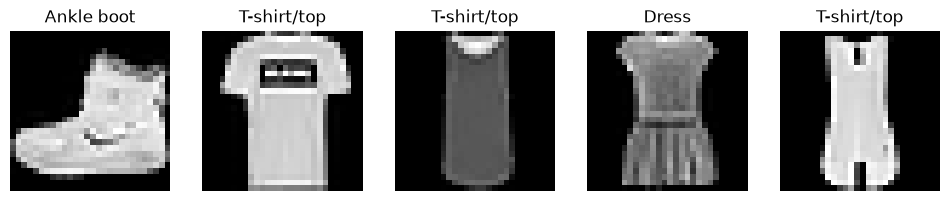

In [25]:
# названия классов идут в порядке их числовых меток (0-9) в датасете
classes = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
           'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

fig, axes = plt.subplots(1, 5, figsize=(12, 3))
for i in range(5):
    image, label = train_dataset[i]
    # squeeze() убирает размерность канала (1, 28, 28) -> (28, 28) для imshow
    axes[i].imshow(image.squeeze(), cmap='gray')
    axes[i].set_title(classes[label])
    axes[i].axis('off')
plt.show()

In [26]:
batch_size = 64

# shuffle=True перемешивает данные перед каждой эпохой — важно для train,
# чтобы модель не привыкала к фиксированному порядку объектов
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
# для test порядок не важен, поэтому shuffle=False
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

# проверяем, что один батч формируется с ожидаемой формой
images, labels = next(iter(train_loader))
print(f"Размер батча изображений: {images.shape}")  # [64, 1, 28, 28]
print(f"Размер батча меток: {labels.shape}")          # [64]

Размер батча изображений: torch.Size([64, 1, 28, 28])
Размер батча меток: torch.Size([64])


In [5]:
class SimpleCNN(nn.Module):
    def __init__(self):
        super().__init__()
        
        # Первый свёрточный слой: 1 входной канал (ч/б), 16 фильтров 3x3
        # padding=1 сохраняет размер карты признаков (28x28 -> 28x28)
        self.conv1 = nn.Conv2d(in_channels=1, out_channels=16, kernel_size=3, padding=1)
        # MaxPool уменьшает карту признаков вдвое, оставляя самый сильный отклик в каждом окне 2x2
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)
        
        # Второй свёрточный слой: 16 -> 32 фильтра, комбинирует простые паттерны
        # первого слоя в более сложные
        self.conv2 = nn.Conv2d(in_channels=16, out_channels=32, kernel_size=3, padding=1)
        
        # после conv1+pool: 28x28 -> 14x14
        # после conv2+pool: 14x14 -> 7x7
        # 32 канала * 7 * 7 = 1568 чисел после flatten
        self.fc1 = nn.Linear(32 * 7 * 7, 128)
        self.dropout = nn.Dropout(0.3)  # отключает 30% нейронов на каждом шаге обучения, борьба с переобучением
        self.fc2 = nn.Linear(128, 10)   # 10 выходов — по одному на класс

    def forward(self, x):
        x = self.pool(torch.relu(self.conv1(x)))   # блок 1: свёртка -> активация -> пулинг
        x = self.pool(torch.relu(self.conv2(x)))   # блок 2: свёртка -> активация -> пулинг
        x = x.view(x.size(0), -1)                   # flatten: разворачиваем карты признаков в один вектор
        x = torch.relu(self.fc1(x))
        x = self.dropout(x)
        x = self.fc2(x)                              # без активации на выходе —
        return x                                      # CrossEntropyLoss сам применит softmax

model = SimpleCNN()
print(model)

SimpleCNN(
  (conv1): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (fc1): Linear(in_features=1568, out_features=128, bias=True)
  (dropout): Dropout(p=0.3, inplace=False)
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)


In [27]:
# используем GPU, если доступен, иначе CPU
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = model.to(device)

criterion = nn.CrossEntropyLoss()   # комбинирует softmax + log loss для многоклассовой классификации
optimizer = optim.Adam(model.parameters(), lr=0.001)  # Adam: инерция + адаптивный шаг для каждого веса

print(f"Обучение на: {device}")

Обучение на: cpu


In [28]:
num_epochs = 10
train_losses = []  # сохраняем историю loss для построения графика
val_losses = []

for epoch in range(num_epochs):
    # --- фаза обучения ---
    model.train()  # включает dropout
    running_loss = 0.0
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        
        optimizer.zero_grad()           # обнуляем градиенты с прошлого шага
        outputs = model(images)          # forward pass
        loss = criterion(outputs, labels)
        loss.backward()                  # backpropagation — считает градиенты
        optimizer.step()                 # обновляет веса по формуле Adam
        
        running_loss += loss.item()
    
    avg_train_loss = running_loss / len(train_loader)
    train_losses.append(avg_train_loss)
    
    # --- фаза проверки (используем test как validation) ---
    model.eval()  # выключает dropout — нужны все нейроны для стабильного предсказания
    val_loss = 0.0
    with torch.no_grad():  # не считаем градиенты — экономит память и ускоряет вычисления
        for images, labels in test_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)
            val_loss += loss.item()
    
    avg_val_loss = val_loss / len(test_loader)
    val_losses.append(avg_val_loss)
    
    print(f"Эпоха {epoch+1}/{num_epochs}: train_loss={avg_train_loss:.4f}, val_loss={avg_val_loss:.4f}")

Эпоха 1/10: train_loss=0.1818, val_loss=0.2459
Эпоха 2/10: train_loss=0.1731, val_loss=0.2426
Эпоха 3/10: train_loss=0.1642, val_loss=0.2473
Эпоха 4/10: train_loss=0.1578, val_loss=0.2481
Эпоха 5/10: train_loss=0.1501, val_loss=0.2482
Эпоха 6/10: train_loss=0.1425, val_loss=0.2498
Эпоха 7/10: train_loss=0.1372, val_loss=0.2492
Эпоха 8/10: train_loss=0.1283, val_loss=0.2580
Эпоха 9/10: train_loss=0.1234, val_loss=0.2595
Эпоха 10/10: train_loss=0.1200, val_loss=0.2829


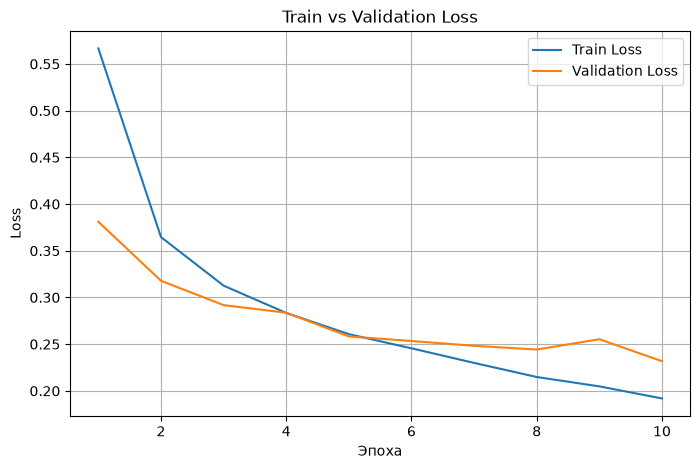

In [18]:
plt.figure(figsize=(8, 5))
plt.plot(range(1, num_epochs+1), train_losses, label='Train Loss')
plt.plot(range(1, num_epochs+1), val_losses, label='Validation Loss')
plt.xlabel('Эпоха')
plt.ylabel('Loss')
plt.title('Train vs Validation Loss')
plt.legend()
plt.grid(True)
plt.savefig('images/loss_plot.png', dpi=150, bbox_inches='tight')
plt.show()

In [29]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

model.eval()
all_preds = []
all_labels = []

# проходим по всему test датасету и собираем предсказания
with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        # torch.max возвращает (значение, индекс) по размерности классов —
        # берём индекс максимального значения как предсказанный класс
        _, predicted = torch.max(outputs, 1)
        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

accuracy = accuracy_score(all_labels, all_preds)
print(f"Test accuracy: {accuracy:.4f}")

cm = confusion_matrix(all_labels, all_preds)

print("\nClassification report:")
print(classification_report(all_labels, all_preds, target_names=classes))

Test accuracy: 0.9081

Classification report:
              precision    recall  f1-score   support

 T-shirt/top       0.83      0.88      0.85      1000
     Trouser       1.00      0.99      0.99      1000
    Pullover       0.77      0.93      0.84      1000
       Dress       0.93      0.91      0.92      1000
        Coat       0.87      0.83      0.85      1000
      Sandal       0.97      0.99      0.98      1000
       Shirt       0.82      0.65      0.73      1000
     Sneaker       0.97      0.95      0.96      1000
         Bag       0.98      0.99      0.99      1000
  Ankle boot       0.97      0.97      0.97      1000

    accuracy                           0.91     10000
   macro avg       0.91      0.91      0.91     10000
weighted avg       0.91      0.91      0.91     10000



In [13]:
cm_df = pd.DataFrame(cm, index=classes, columns=classes)
print(cm_df)

             T-shirt/top  Trouser  Pullover  Dress  Coat  Sandal  Shirt  \
T-shirt/top          907        0        11     14     3       1     59   
Trouser                0      989         0      7     1       0      1   
Pullover              17        0       867      8    48       0     59   
Dress                 16        5         9    929    18       0     23   
Coat                   2        1        51     29   860       0     57   
Sandal                 0        0         0      0     0     988      0   
Shirt                129        2        57     28    60       0    720   
Sneaker                0        0         0      0     0      14      0   
Bag                    3        1         0      2     0       2      1   
Ankle boot             0        0         0      0     0       6      0   

             Sneaker  Bag  Ankle boot  
T-shirt/top        0    5           0  
Trouser            0    2           0  
Pullover           0    1           0  
Dress         

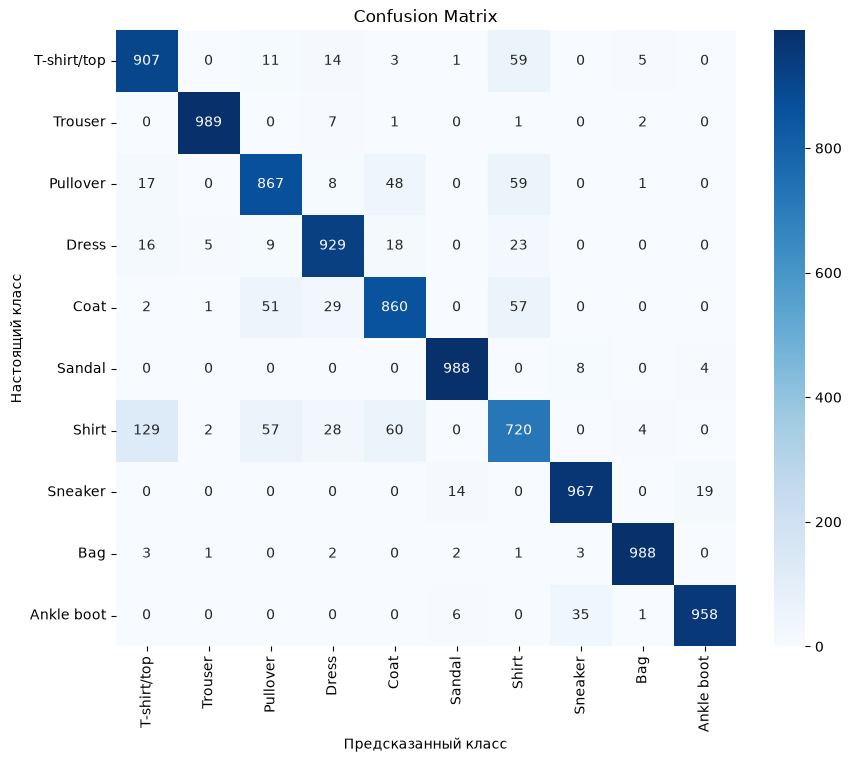

In [20]:
plt.figure(figsize=(10, 8))
sns.heatmap(cm_df, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Предсказанный класс')
plt.ylabel('Настоящий класс')
plt.title('Confusion Matrix')
plt.savefig('images/confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()

Всего ошибок: 827 из 10000


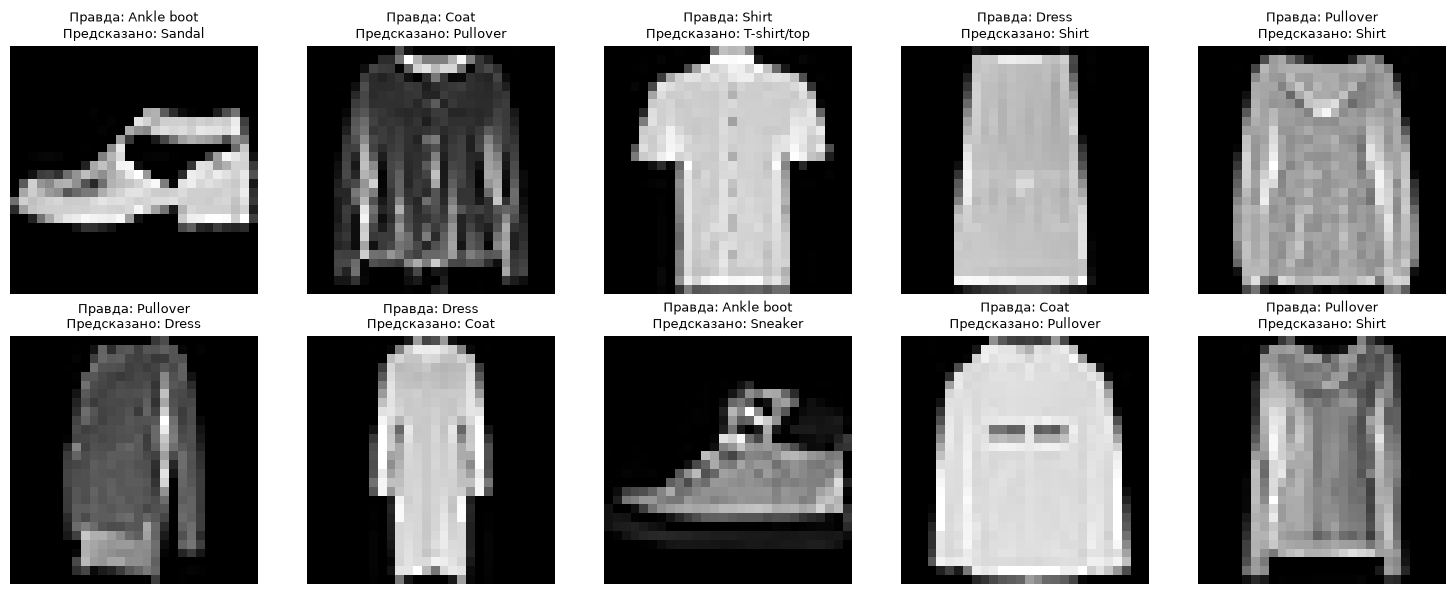

In [17]:
# находим индексы, где предсказание не совпало с настоящим классом
all_preds = np.array(all_preds)
all_labels = np.array(all_labels)
wrong_indices = np.where(all_preds != all_labels)[0]

print(f"Всего ошибок: {len(wrong_indices)} из {len(all_labels)}")

# берём первые 10 ошибок для показа
fig, axes = plt.subplots(2, 5, figsize=(15, 6))
axes = axes.flatten()

for i, idx in enumerate(wrong_indices[:10]):
    image, _ = test_dataset[idx]
    true_label = classes[all_labels[idx]]
    pred_label = classes[all_preds[idx]]
    
    axes[i].imshow(image.squeeze(), cmap='gray')
    axes[i].set_title(f"Правда: {true_label}\nПредсказано: {pred_label}", fontsize=9)
    axes[i].axis('off')

plt.tight_layout()
plt.show()